**Clinical Note Routing: Leakage-Free, Explainable Specialty Classification of Medical Transcriptions**

MAAI 902 Natural Language Processing & LLMs ·
Assessment Task 2: NLP Solution Design ·

**Student name:** Nourhanne Abdelaziz

**Student Numer:** 1113173

Part I


# Part 1: Data Understanding, Cleaning and Pre-processing
**Clinical Note Routing · MAAI 902 Task 2**

This notebook is **self-contained** and runs in Google Colab with no other project files. It covers:

* **A. Data understanding:** structure, missing values, labels, text length, duplicates and leakage
* **B. Data cleaning:** six documented steps, each with before/after evidence
* **C. Pre-processing for modelling:** tokenisation, stop-words, lemmatisation, TF-IDF, BERT tokens, label encoding and leakage-free folds

**How to run in Colab:** *File → Upload notebook*, choose this file, then *Runtime → Run all*. When asked, upload `Healthcare_Documentation_Database.csv`. Cells marked **[Colab]** download NLTK/spaCy/Hugging Face resources and need internet.

In [3]:
# ---- Setup -----------------------------------------------------------------
import os, re, json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#52514e"
SEED = 42

CSV = "Healthcare_Documentation_Database.csv"
# In Colab: upload the file once. Locally: look in the usual project folders.
try:
    from google.colab import files
    if not os.path.exists(CSV):
        files.upload()
except ImportError:
    for p in [CSV, os.path.join("..", "data", CSV), os.path.join("data", CSV)]:
        if os.path.exists(p):
            CSV = p
            break

df = pd.read_csv(CSV)
print("Loaded", CSV, "->", df.shape)

Loaded Healthcare Documentation Database.csv -> (3813, 7)


## A. Data understanding
### A1. Structure and data types

In [4]:
buf = __import__("io").StringIO(); df.info(buf=buf); print(buf.getvalue())
df.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3813 entries, 0 to 3812
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Serial No              3813 non-null   int64 
 1   description            3813 non-null   object
 2   medical_specialty      3813 non-null   object
 3   sample_name            3813 non-null   object
 4   transcription          3813 non-null   object
 5   keywords               3813 non-null   object
 6   cleaned_transcription  3813 non-null   object
dtypes: int64(1), object(6)
memory usage: 208.7+ KB



,Serial No,description,medical_specialty,sample_name,transcription,keywords,cleaned_transcription
0,0,A 23-year-old white female presents with complaint of allergies.,Allergy / Immunology,Allergic Rhinitis,"subjective:, this 23-year-old white female presents with complaint of allergies. she...","allergy / immunology, allergic rhinitis, allergies, asthma, nasal sprays, rhinitis, na...",subjective 23yearold white female present complaint allergy used allergy lived seat...
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"past medical history:, he has difficulty climbing stairs, difficulty with airline seat...","bariatrics, laparoscopic gastric bypass, weight loss programs, gastric bypass, atkin's...",past medical history difficulty climbing stair difficulty airline seat tying shoe ...
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"history of present illness: , i have seen abc today. he is a very pleasant gentleman ...","bariatrics, laparoscopic gastric bypass, heart attacks, body weight, pulmonary embolis...",history present illness seen abc today pleasant gentleman 42 year old 344 pound 5...


| Column | What it holds |
|---|---|
| `Serial No` | Row index |
| `description` | One-line human summary of the note |
| `medical_specialty` | **Target label** (one per row) |
| `sample_name` | Title of the sample |
| `transcription` | **Full note text: the model input** |
| `keywords` | Comma-separated key terms |
| `cleaned_transcription` | A pre-cleaned copy provided with the dataset |

### A2. Missing and empty values

In [5]:
missing = pd.DataFrame({
    "null values": df.isna().sum(),
    "empty strings": df.apply(lambda c: (c.astype(str).str.strip() == "").sum()),
})
missing

,null values,empty strings
Serial No,0,0
description,0,0
medical_specialty,0,0
sample_name,0,0
transcription,0,0
keywords,0,0
cleaned_transcription,0,0


No nulls and no empty strings, so no imputation is needed. Quality problems here are *semantic* (duplicates, leakage, label design), not missing data.

### A3. The target: medical specialty labels

Number of labels: 39
Largest / smallest: 1007 / 3  ->  imbalance 336:1


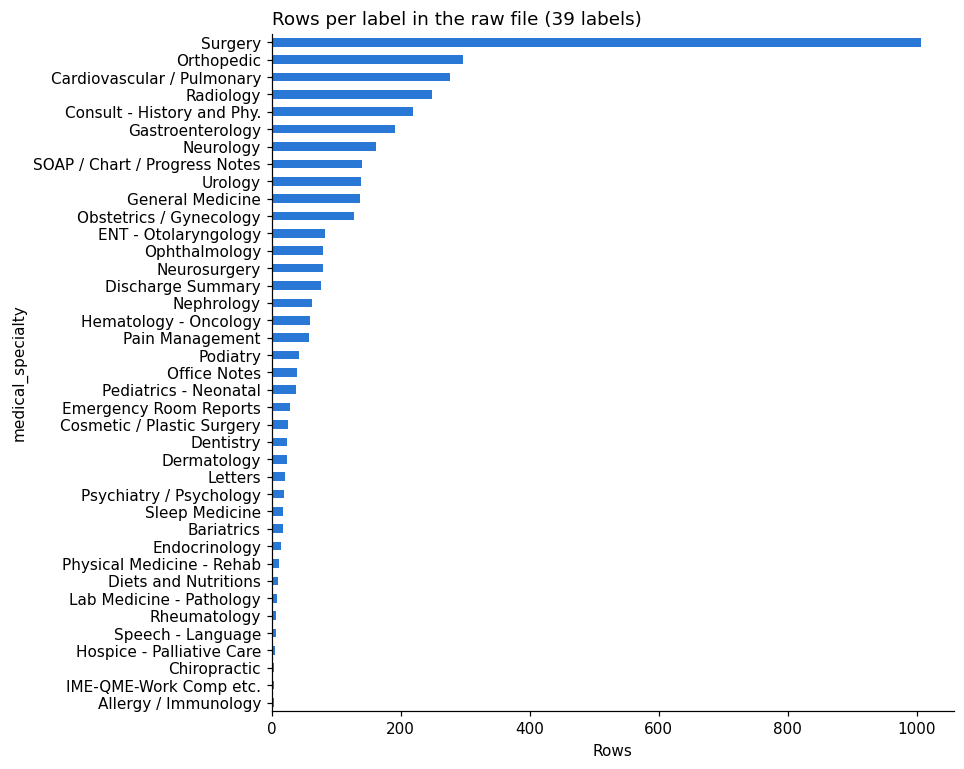

In [6]:
df["medical_specialty"] = df["medical_specialty"].str.strip()   # labels carry a leading space
counts = df["medical_specialty"].value_counts()
print("Number of labels:", counts.size)
print(f"Largest / smallest: {counts.iloc[0]} / {counts.iloc[-1]}  ->  imbalance {counts.iloc[0] / counts.iloc[-1]:.0f}:1")
fig, ax = plt.subplots(figsize=(8, 8))
counts.sort_values().plot.barh(ax=ax, color=BLUE)
ax.set_xlabel("Rows"); ax.set_title("Rows per label in the raw file (39 labels)", loc="left")
plt.show()

Two observations:

* **Severe imbalance:** Surgery has 1,007 rows and Allergy / Immunology has 3. Accuracy would reward always predicting Surgery, so **macro-F1** is needed.
* **Mixed taxonomy:** some labels are **document types**, not specialties: *Consult – History and Phy.*, *SOAP / Chart / Progress Notes*, *Discharge Summary*, *Office Notes*, *Letters*, *Emergency Room Reports*, *IME-QME-Work Comp etc.*

### A4. Text length

,n_words,n_chars
count,3813.0,3813.0
mean,404.0,2643.0
std,264.0,1659.0
min,1.0,11.0
25%,214.0,1433.0
50%,342.0,2292.0
75%,538.0,3487.0
max,1873.0,11046.0


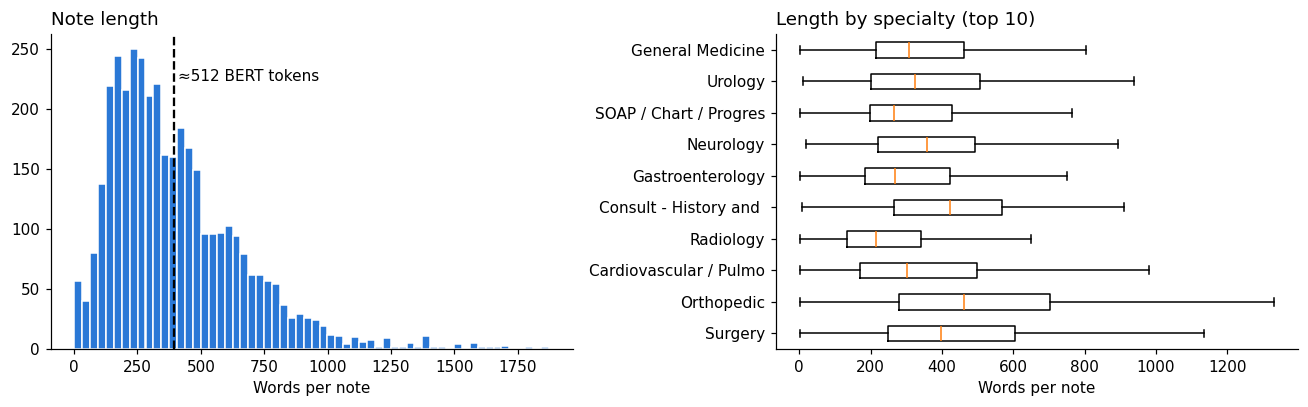

Notes longer than ~394 words (≈512 WordPiece tokens at 1.3 tokens/word): 43%
Very short notes (< 20 words): 51


In [7]:
df["n_words"] = df["transcription"].astype(str).str.split().str.len()
df["n_chars"] = df["transcription"].astype(str).str.len()
display(df[["n_words", "n_chars"]].describe().round(0))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(df["n_words"], bins=60, color=BLUE, edgecolor="white")
axes[0].axvline(394, color="black", ls="--"); axes[0].text(410, axes[0].get_ylim()[1]*0.85, "≈512 BERT tokens")
axes[0].set_xlabel("Words per note"); axes[0].set_title("Note length", loc="left")
top10 = counts.index[:10]
data = [df.loc[df.medical_specialty == s, "n_words"] for s in top10]
axes[1].boxplot(data, vert=False, showfliers=False)
axes[1].set_yticks(range(1, 11), [s[:22] for s in top10])   # works on every matplotlib version
axes[1].set_xlabel("Words per note"); axes[1].set_title("Length by specialty (top 10)", loc="left")
plt.tight_layout(); plt.show()
print(f"Notes longer than ~394 words (≈512 WordPiece tokens at 1.3 tokens/word): {(df.n_words > 394).mean():.0%}")
print("Very short notes (< 20 words):", (df.n_words < 20).sum())

Many notes are longer than a standard BERT window, so a transformer must **chunk** them or use a long-context model. A few notes are almost empty and carry no signal.

### A5. What a raw note looks like

In [8]:
note = df.loc[df.medical_specialty == "Gastroenterology", "transcription"].iloc[3]
print(note[:700])

history of present illness: , patient is a 40-year-old white female visiting with her husband complaining of the onset of nausea and vomiting approximately at 11 p.m. last night, after she states she drank "lots of red wine."  she states after vomiting, she felt "fine through the night," but woke with more nausea and vomiting and diaphoresis.  she states she has vomited approximately 20 times today and has also had some slight diarrhea.  she denies any sore throat or cough.  she states no one else at home has been ill.  she has not taken anything for her symptoms.,medications: , currently the patient is on fluoxetine for depression and zyrtec for environmental allergies.,allergies: , she has


The text is already lower-case. Line breaks were flattened into `.,` and empty fields into `: ,`. Section headers such as *preoperative diagnosis:* are informative, so they are kept.

### A6. Duplicates: the most important finding

In [9]:
print("Fully duplicated rows:", df.duplicated().sum())
t = df["transcription"].str.strip()
print("Unique transcriptions:", t.nunique(), "of", len(df), "rows")

label_sets = df.assign(t=t).groupby("t")["medical_specialty"].agg(lambda s: tuple(sorted(set(s))))
print("Transcriptions filed under 2+ labels:", (label_sets.map(len) > 1).sum())
print("Average labels per unique transcription:", round(label_sets.map(len).mean(), 2))
label_sets[label_sets.map(len) > 1].value_counts().head(8).rename("notes").to_frame()

Fully duplicated rows: 0
Unique transcriptions: 1823 of 3813 rows
Transcriptions filed under 2+ labels: 1651
Average labels per unique transcription: 2.09


,notes
medical_specialty,
"(Orthopedic, Surgery)",144
"(Gastroenterology, Surgery)",136
"(Cardiovascular / Pulmonary, Surgery)",131
"(Surgery, Urology)",88
"(Obstetrics / Gynecology, Surgery)",84
"(Cardiovascular / Pulmonary, Radiology)",64
"(Ophthalmology, Surgery)",55
"(ENT - Otolaryngology, Surgery)",51


No row is an exact duplicate, but the same **text** appears under several labels. A knee arthroscopy is filed under *Orthopedic* **and** *Surgery*. Consequences:

1. The task is **multi-label**: one note can belong to several specialties.
2. A random row split puts the same text in train and test, which is **leakage**.
3. As a single-label problem it is contradictory: one text, two "correct" answers.

### A7. Leakage audit of the other columns

In [10]:
starts = df.apply(lambda r: str(r["keywords"]).strip().lower().startswith(r["medical_specialty"].lower()), axis=1)
print(f"keywords starts with the label: {starts.mean():.0%} of rows")
df[["medical_specialty", "keywords"]].sample(4, random_state=SEED)

keywords starts with the label: 100% of rows


,medical_specialty,keywords
3290,Cosmetic / Plastic Surgery,"cosmetic / plastic surgery, skin graft, lower extremities, split thickness skin grafti..."
3053,ENT - Otolaryngology,"ent - otolaryngology, frontal sinus, nasal septal, transconjunctival, anterior table, ..."
599,Surgery,"surgery, pelvic pain, hypermenorrhea, endometriosis, dilatation and curettage, d&c, en..."
2221,Obstetrics / Gynecology,"obstetrics / gynecology, intrauterine pregnancy, gestation, preterm labor, omentum adh..."


* `keywords` **contains the answer** in 100% of rows, so it must never be an input.
* `description` and `sample_name` are human summaries that would not exist when a new note arrives, so they are also excluded.
* **Only `transcription` is used as input.**

### A8. The provided `cleaned_transcription` column

In [11]:
i = df.index[df.medical_specialty == "Gastroenterology"][3]
print("ORIGINAL:", df.loc[i, "transcription"][:250], "\n")
print("PROVIDED CLEANED:", df.loc[i, "cleaned_transcription"][:250])
ratio = (df.cleaned_transcription.str.split().str.len() / df.n_words).median()
print(f"\nThe provided cleaned text keeps a median {ratio:.0%} of the words")

ORIGINAL: history of present illness: , patient is a 40-year-old white female visiting with her husband complaining of the onset of nausea and vomiting approximately at 11 p.m. last night, after she states she drank "lots of red wine."  she states after vomiti 

PROVIDED CLEANED: history present illness   patient 40yearold white female visiting husband complaining onset nausea vomiting approximately 11 pm last night  state drank  lot red wine   state vomiting  felt  fine night   woke nausea vomiting diaphoresis  state vomited

The provided cleaned text keeps a median 61% of the words


The provided column has stop-words and punctuation removed, which breaks phrases such as *"no evidence of"*. Transformers need the full sentence, so this project rebuilds its own cleaning from the original text and documents every step.

### A9. Vocabulary before cleaning

In [12]:
tokens = re.findall(r"[a-z]{2,}", " ".join(df["transcription"].str.lower()))
print("Total tokens:", f"{len(tokens):,}", "| distinct:", f"{len(set(tokens)):,}")
pd.DataFrame(Counter(tokens).most_common(15), columns=["token", "count"]).T

Total tokens: 1,495,356 | distinct: 17,453


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
token,the,was,and,of,to,with,in,patient,is,were,for,then,this,she,on
count,112804,57181,56757,39270,35013,25490,22747,15818,14188,12451,10813,10402,9902,9376,9279


The most frequent tokens are function words (*the, and, was…*) that carry no specialty signal, which is why stop-word removal matters for the bag-of-words model.

## B. Data cleaning
Each step answers a finding from Part A.
### B1. Keep only the input and target columns

In [13]:
data = df[["transcription", "medical_specialty"]].copy()
print("Columns kept:", list(data.columns), "| dropped: keywords, description, sample_name, cleaned_transcription, Serial No")

Columns kept: ['transcription', 'medical_specialty'] | dropped: keywords, description, sample_name, cleaned_transcription, Serial No


### B2. Normalise the text

In [14]:
def clean_text(text: str) -> str:
    text = str(text).lower()                  # 1. lower-case
    text = re.sub(r"[^a-z0-9\s]", " ", text)  # 2. punctuation and '.,' artefacts -> space (keeps numbers like 'c5', '35')
    return re.sub(r"\s+", " ", text).strip()   # 3. collapse whitespace

data["text"] = data["transcription"].map(clean_text)
print("BEFORE:", data["transcription"].iloc[5][:200])
print("AFTER: ", data["text"].iloc[5][:200])

BEFORE: preoperative diagnosis: , morbid obesity.,postoperative diagnosis:  ,morbid obesity.,procedure: , laparoscopic antecolic antegastric roux-en-y gastric bypass with eea anastomosis.,anesthesia: , genera
AFTER:  preoperative diagnosis morbid obesity postoperative diagnosis morbid obesity procedure laparoscopic antecolic antegastric roux en y gastric bypass with eea anastomosis anesthesia general with endotrac


### B3. De-duplicate and merge labels into sets

In [15]:
notes = data.groupby("text")["medical_specialty"].agg(lambda s: sorted(set(s))).reset_index()
notes = notes.rename(columns={"medical_specialty": "labels"})
print(f"{len(data)} rows -> {len(notes)} unique notes ({len(data) - len(notes)} duplicate rows merged)")
notes.head()

3813 rows -> 1821 unique notes (1992 duplicate rows merged)


,text,labels
0,1 odynophagia 2 dysphagia 3 gastroesophageal reflux disease rule out stricture postope...,"[Gastroenterology, Surgery]"
1,1 pelvic tumor 2 cystocele 3 rectocele postoperative diagnoses 1 degenerated joint 2 u...,"[Obstetrics / Gynecology, Surgery, Urology]"
2,1 the left ventricular cavity size and wall thickness appear normal the wall motion an...,"[Cardiovascular / Pulmonary, Radiology]"
3,2 d echocardiogram multiple views of the heart and great vessels reveal normal intraca...,"[Cardiovascular / Pulmonary, Radiology]"
4,2 d m mode 1 left atrial enlargement with left atrial diameter of 4 7 cm 2 normal size...,"[Cardiovascular / Pulmonary, Radiology]"


### B4. Fix the label taxonomy

In [16]:
DOCUMENT_TYPES = {"Consult - History and Phy.", "SOAP / Chart / Progress Notes", "Discharge Summary",
                  "Office Notes", "Letters", "Emergency Room Reports", "IME-QME-Work Comp etc."}
MIN_SUPPORT = 15   # fewer notes than this -> <= 3 positives per test fold, F1 becomes noise

notes["labels"] = notes["labels"].map(lambda ls: [l for l in ls if l not in DOCUMENT_TYPES])
support = Counter(l for ls in notes["labels"] for l in ls)
rare = sorted(l for l, n in support.items() if n < MIN_SUPPORT)
keep = sorted(l for l, n in support.items() if n >= MIN_SUPPORT)
notes["labels"] = notes["labels"].map(lambda ls: [l for l in ls if l in keep])
print("Removed document-type labels:", len(DOCUMENT_TYPES))
print("Removed rare specialties:", {l: support[l] for l in rare})
print("Specialties kept:", len(keep))

Removed document-type labels: 7
Removed rare specialties: {'Allergy / Immunology': 3, 'Chiropractic': 4, 'Diets and Nutritions': 10, 'Hospice - Palliative Care': 5, 'Lab Medicine - Pathology': 8, 'Physical Medicine - Rehab': 11, 'Rheumatology': 7, 'Speech - Language': 7}
Specialties kept: 24


### B5. Remove unusable notes

In [17]:
notes["n_words"] = notes["text"].str.split().str.len()
no_label = notes["labels"].str.len() == 0
too_short = notes["n_words"] < 20
print("Notes with no specialty left:", no_label.sum())
print("Notes under 20 words:", (too_short & ~no_label).sum())
notes = notes[~no_label & ~too_short].reset_index(drop=True)
print("Final notes:", len(notes))

Notes with no specialty left: 47
Notes under 20 words: 23
Final notes: 1751


### B6. Clean dataset summary

,value
raw rows,3813
unique notes,1821
final notes,1751
labels (raw -> final),39 -> 24
labels per note,1.82
median words,356
90th percentile words,765


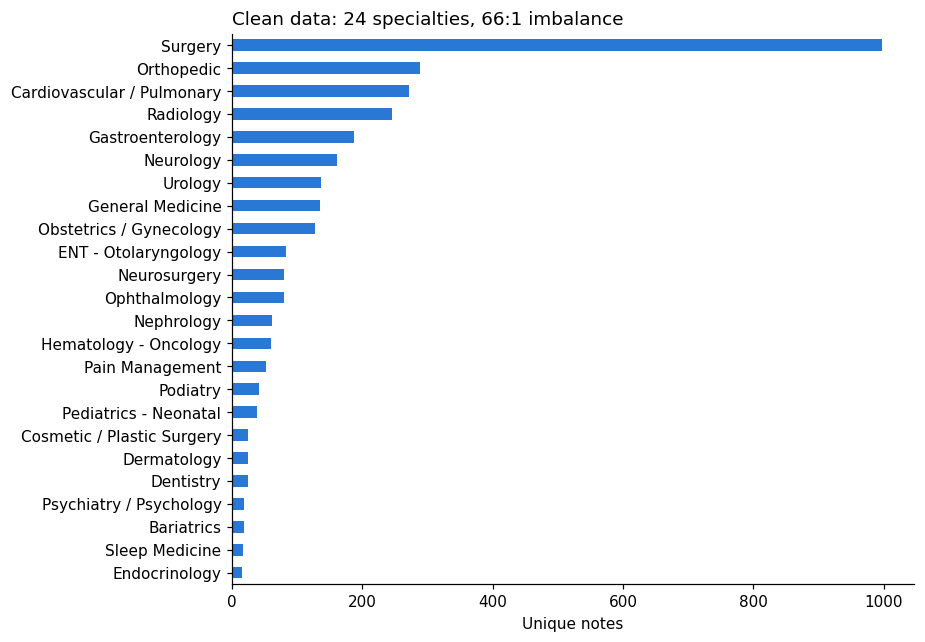

In [18]:
summary = pd.Series({
    "raw rows": len(df), "unique notes": len(data["text"].unique()), "final notes": len(notes),
    "labels (raw -> final)": f"{df.medical_specialty.nunique()} -> {len(keep)}",
    "labels per note": round(notes["labels"].str.len().mean(), 2),
    "median words": int(notes["n_words"].median()), "90th percentile words": int(notes["n_words"].quantile(.9)),
})
display(summary.to_frame("value"))
final_support = pd.Series(Counter(l for ls in notes["labels"] for l in ls)).sort_values()
fig, ax = plt.subplots(figsize=(8, 6.5))
final_support.plot.barh(ax=ax, color=BLUE); ax.set_xlabel("Unique notes")
ax.set_title(f"Clean data: 24 specialties, {final_support.max() / final_support.min():.0f}:1 imbalance", loc="left")
plt.show()

## C. Pre-processing for modelling
### C1. Tokenisation and stop-word removal

In [19]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
example = notes["text"].iloc[10]
toks = re.findall(r"\b\w\w+\b", example)         # same token pattern as scikit-learn
content = [w for w in toks if w not in ENGLISH_STOP_WORDS]
print("tokens:", len(toks), "-> after stop-words:", len(content), f"({1 - len(content)/len(toks):.0%} removed)")
print("first 25 kept:", content[:25])

tokens: 133 -> after stop-words: 75 (44% removed)
first 25 kept: ['acromioclavicular', 'joint', 'injection', 'procedure', 'informed', 'consent', 'obtained', 'patient', 'possible', 'complications', 'mentioned', 'including', 'joint', 'swelling', 'infection', 'bruising', 'joint', 'prepared', 'betadine', 'alcohol', 'ml', 'depo', 'medrol', 'ml', '25']


### C2. Tokenisation with NLTK and lemmatisation with spaCy **[Colab]**
These libraries download models, so run this cell in Colab. It compares tokenisers and shows lemmatisation. Lemmatisation was tested but **not used** in the final TF-IDF model, because clinical suffixes carry meaning (e.g. *-ectomy* vs *-otomy*) and the unigram model already reached its plateau.

In [20]:
!pip -q install nltk spacy
!python -m spacy download en_core_web_sm -q
import nltk, spacy
nltk.download("punkt", quiet=True); nltk.download("punkt_tab", quiet=True); nltk.download("stopwords", quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

raw = df["transcription"].iloc[10][:300]
print("NLTK tokens:", word_tokenize(raw)[:20])
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
doc = nlp(raw)
print("spaCy lemmas:", [(t.text, t.lemma_) for t in doc if t.is_alpha][:20])
print("NLTK stop-words:", len(stopwords.words("english")), "| scikit-learn stop-words:", len(ENGLISH_STOP_WORDS))

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
NLTK tokens: ['preoperative', 'diagnosis', ':', ',', 'morbid', 'obesity', '.', ',', 'postoperative', 'diagnosis', ':', ',', 'morbid', 'obesity', '.', ',', 'procedure', ':', ',', 'laparoscopic']
spaCy lemmas: [('preoperative', 'preoperative'), ('diagnosis', 'diagnosis'), ('morbid', 'morbid'), ('obesity', 'obesity'), ('postoperative', 'postoperative'), ('diagnosis', 'diagnosis'), ('morbid', 'morbid'), ('obesity', 'obesity'), ('procedure', 'procedure'), ('laparoscopic', 'laparoscopic'), ('roux', 'roux'), ('en', 'en'), ('y', 'y'), ('gastric', 'gastric'), ('bypass', 'bypass'), ('antecolic', 'antecolic'), ('antegastric', 'antegastric'), ('with', 'with'), ('mm', 

### C3. TF-IDF representation

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer(ngram_range=(1, 1), min_df=2, max_df=0.9, sublinear_tf=True, stop_words="english")
X = vec.fit_transform(notes["text"])
print("Matrix:", X.shape, f"| sparsity {1 - X.nnz / (X.shape[0] * X.shape[1]):.2%}")
print("min_df=2 drops typos and one-off details; max_df=0.9 drops words in >90% of notes; sublinear_tf dampens long notes.")

vocab = np.array(vec.get_feature_names_out())
rows = {}
for spec in ["Ophthalmology", "Urology", "Neurology", "Cardiovascular / Pulmonary", "Psychiatry / Psychology"]:
    mask = notes["labels"].map(lambda ls: spec in ls).values
    mean = np.asarray(X[mask].mean(0)).ravel()
    rows[spec] = ", ".join(vocab[np.argsort(-mean)[:8]])
pd.Series(rows, name="highest mean TF-IDF words").to_frame()

Matrix: (1751, 11017) | sparsity 98.69%
min_df=2 drops typos and one-off details; max_df=0.9 drops words in >90% of notes; sublinear_tf dampens long notes.


,highest mean TF-IDF words
Ophthalmology,"eye, chamber, lid, lens, cataract, intraocular, speculum, limbus"
Urology,"bladder, patient, prostate, procedure, placed, urethra, using, inguinal"
Neurology,"right, left, mri, exam, brain, unremarkable, normal, motor"
Cardiovascular / Pulmonary,"left, chest, artery, right, patient, coronary, procedure, heart"
Psychiatry / Psychology,"axis, disorder, mother, history, depression, behavior, years, problems"


Distinctive clinical words (*cataract, prostate, mri*) rank near the top for each specialty, so the cleaned text keeps the signal needed for routing. Generic procedure words (*patient, placed, using*) also rank high because a mean TF-IDF does not discount words that other specialties share. The classifier's learned weights do discount them, as the modelling notebook shows.

### C4. BERT tokenisation and chunking of long notes **[Colab]**
This counts real WordPiece tokens with the Bio_ClinicalBERT tokenizer and shows how one long note becomes overlapping 512-token windows.

In [22]:
!pip -q install transformers
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")
lengths = notes["text"].map(lambda t: len(tok(t)["input_ids"]))
print(f"WordPiece tokens: median {lengths.median():.0f}, > 512 for {(lengths > 512).mean():.0%} of notes")
longest = notes["text"].iloc[lengths.idxmax()]
enc = tok(longest, truncation=True, max_length=512, stride=128, return_overflowing_tokens=True)
print("Longest note:", lengths.max(), "tokens ->", len(enc["input_ids"]), "overlapping windows")

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

WordPiece tokens: median 480, > 512 for 46% of notes
Longest note: 2293 tokens -> 6 overlapping windows


### C5. Encode the labels (multi-label)

In [23]:
from sklearn.preprocessing import MultiLabelBinarizer
mlb = MultiLabelBinarizer(classes=keep)
Y = mlb.fit_transform(notes["labels"])
print("Label matrix:", Y.shape)
print("Label cardinality (labels per note):", round(Y.sum(1).mean(), 2))
print("Label density:", round(Y.mean(), 3))
pd.DataFrame(Y[:3], columns=keep).loc[:, lambda d: d.any()]

Label matrix: (1751, 24)
Label cardinality (labels per note): 1.82
Label density: 0.076


,Cardiovascular / Pulmonary,Gastroenterology,Obstetrics / Gynecology,Radiology,Surgery,Urology
0,0,1,0,0,1,0
1,0,0,1,0,1,1
2,1,0,0,1,0,0


### C6. Leakage-free cross-validation folds
Standard stratified K-fold supports one label per item. **Iterative stratification** (Sechidis *et al.*, 2011) assigns notes so every specialty is spread evenly across folds, rarest label first. Folds are built on **unique notes**, so no text can be in both train and test.

In [24]:
def iterative_stratified_folds(Y, n_folds=5, seed=42):
    rng = np.random.default_rng(seed)
    n = len(Y)
    fold = -np.ones(n, dtype=int)
    want_total = np.full(n_folds, n / n_folds)                 # notes each fold still wants
    want_label = np.tile(Y.sum(0) / n_folds, (n_folds, 1))     # label occurrences each fold still wants
    left = np.ones(n, dtype=bool)
    while left.any():
        c = Y[left].sum(0).astype(float); c[c == 0] = np.inf
        lab = int(np.argmin(c))                                  # rarest remaining label
        for i in rng.permutation(np.where(left & (Y[:, lab] == 1))[0]):
            cand = np.flatnonzero(want_label[:, lab] == want_label[:, lab].max())
            cand = cand[want_total[cand] == want_total[cand].max()]
            f = int(rng.choice(cand))
            fold[i], left[i] = f, False
            want_label[f] -= Y[i]; want_total[f] -= 1
    return fold

notes["fold"] = iterative_stratified_folds(Y, 5, SEED)
check = pd.DataFrame({f"fold {k}": Y[notes.fold == k].sum(0) for k in range(5)}, index=keep)
print("Notes per fold:", np.bincount(notes["fold"]))
check.sort_values("fold 0").head(8)

Notes per fold: [350 354 347 352 348]


,fold 0,fold 1,fold 2,fold 3,fold 4
Bariatrics,3,4,4,3,4
Endocrinology,3,3,3,3,3
Dermatology,4,5,5,5,5
Psychiatry / Psychology,4,3,4,4,4
Sleep Medicine,4,3,3,4,3
Cosmetic / Plastic Surgery,5,5,5,5,5
Dentistry,5,5,5,5,4
Pediatrics - Neonatal,7,8,8,7,8


Even the rarest specialties (Endocrinology, Sleep Medicine) appear in every fold, so per-label F1 can be measured in each test split.

### C7. Save the clean dataset

In [25]:
out = notes.assign(labels=notes["labels"].str.join("|"))[["text", "labels", "n_words", "fold"]]
out.to_csv("notes_clean.csv", index=False)
print("Saved notes_clean.csv:", out.shape)
out.head(3)

Saved notes_clean.csv: (1751, 4)


,text,labels,n_words,fold
0,1 odynophagia 2 dysphagia 3 gastroesophageal reflux disease rule out stricture postope...,Gastroenterology|Surgery,252,4
1,1 pelvic tumor 2 cystocele 3 rectocele postoperative diagnoses 1 degenerated joint 2 u...,Obstetrics / Gynecology|Surgery|Urology,1127,3
2,1 the left ventricular cavity size and wall thickness appear normal the wall motion an...,Cardiovascular / Pulmonary|Radiology,241,0


## Summary

| Finding (Part A) | Action (Parts B and C) |
|---|---|
| `keywords` contains the label in 100% of rows | Dropped; only `transcription` is used |
| 3,813 rows = 1,821 unique texts, 2.09 labels each | De-duplicated; treated as **multi-label** |
| 7 labels are document types, 8 have < 15 notes | Removed; **24 specialties** kept |
| 66:1 imbalance after cleaning | Macro-F1 as primary metric; class-weighted loss |
| ~45% of notes exceed 512 BERT tokens | Chunking with stride, or a long-context model |
| Function words dominate raw counts | Stop-words removed inside TF-IDF only |
| Random row splits leak duplicate text | Iterative-stratified folds on unique notes |

**Output:** `notes_clean.csv` (1,751 notes, 24 labels, 5 folds), the input for the modelling notebook `clinical_note_routing.ipynb`.